# **PHYS 249: Assignment 2 - The Invisible Patient: Reconstructing an Image**

##### $\text{\it{Basil Droulias, Owen Dumancic}}$

### $\text{Part A}$

The variables $x_1,\dotsc,x_4$ represent each pixel of the object's linear attenuation coefficient, how much intensity an X-ray loses by passing through the corresponding pixel. We can deduce both that each $x_i$ must be nonnegative, and the effect of a larger $x_i$ on $I$, by analyzing the mathematical relationships provided in the imaging model; examining them, we find

$$ I = I_0e^{-(\ell \cdot \boldsymbol{x})} = \frac{I_0}{e^{\ell \cdot \boldsymbol{x}}}$$

Firstly, suppose we are have the path-length vector $\ell = (1,0,0,0)$ and $x_1 < 0$; then $\ell \cdot \boldsymbol{x} < 0$, and our expression for $I$ says $I > I_0$, meaning the X-ray gained intensity from the interaction with the material - something not physically possible in this case. Secondly, suppose we have the same $\ell$ but with $x_1 > 0$; as $x_1$ grows, the denominator grows, and so the measured intensity decreases.

The reason we can represent an X-ray intensity measurement as a dot product results from the physical meanings of $\ell$ and $\boldsymbol{x}$. Once again, examining our mathematical model we find

$$I = \frac{I_0}{e^{\ell \cdot \boldsymbol{x}}} = \frac{I_0}{e^{\sum\limits_{j=1}^{4}{\ell_j x_j}}} = \sum\limits_{j=1}^4 \frac{I_0}{4e^{\ell_j x_j}} = \frac{I_0}{4e^{\ell_1 x_1}} + \frac{I_0}{4e^{\ell_2 x_2}} + \frac{I_0}{4e^{\ell_3 x_3}} + \frac{I_0}{4e^{\ell_4 x_4}}$$

### $\text{Part D}$

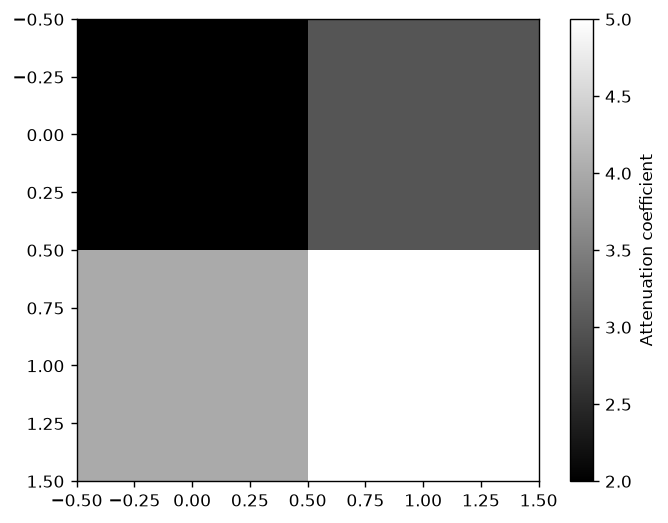

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

A = np.array([[1, 1, 0, 0], [0, 0, 1, 1], [1, 0, 1, 0], [1, 0, 0, 1]]) # initialize coefficient matrix A
b = np.array([[5], [9], [6], [7]]) # initialize measurement vector b

x = np.linalg.solve(A, b).reshape(2, 2) # find solution vector x and reshape into a 2x2 matrix [x1 x2 / x3 x4]

# display the 2x2 solution matrix for x
plt.imshow(x, cmap="gray", interpolation="nearest")
plt.colorbar(label="Attenuation coefficient")
plt.show()

We observe that pixel 4 has the greatest attenuation, meaning that physically, it reduces X-ray intensity the **most** of all 4 pixels.

In [25]:
print(np.allclose(A @ x.reshape(-1, 1), b))

True
